In [20]:
# Imports + model/metric setup. Fraud is rare, so PR-AUC and Brier score matter more than plain accuracy.
# Output: confirms whether XGBoost is installed (falls back to HistGradientBoosting if not).
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve, roc_curve, brier_score_loss

from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
try:
    from xgboost import XGBClassifier; HAS_XGB = True
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier; HAS_XGB = False

rng = np.random.default_rng(42)
print("XGBoost available:", HAS_XGB)

XGBoost available: True


In [21]:
# Generates synthetic transactions: per-customer behavior, a smooth fraud-risk signal (new device,
# foreign, risky category, amount deviation, channel), plus 45 injected "account takeover" bursts.
# Output: total transaction count, fraud count, and overall fraud rate (~0.9%, close to the 0.6% target).
N_CUST, DAYS = 2000, 60
CATS = np.array(["grocery","fuel","restaurant","online_retail","travel","electronics","gift_cards","crypto"])
CAT_P = np.array([.30,.12,.18,.18,.05,.09,.05,.03]) 
RISKY = ["travel","electronics","gift_cards","crypto"]
CHAN = np.array(["pos","ecom","atm","wallet"]); CH_P = [.45,.35,.08,.12]

rate = rng.lognormal(np.log(0.7), 0.6, N_CUST)            # txns/day per customer
mu = rng.normal(np.log(40), 0.5, N_CUST)                  # customer's typical log-amount
two_dev = rng.random(N_CUST) < 0.3

cid = np.repeat(np.arange(N_CUST), rng.poisson(rate * DAYS))
n = len(cid)
hour = np.where(rng.random(n) < .85, rng.integers(8, 22, n), rng.integers(0, 24, n))
ts = rng.integers(0, DAYS, n) * 86400 + hour * 3600 + rng.integers(0, 3600, n)
amount = np.round(rng.lognormal(mu[cid], .55), 2)
cat, chan = rng.choice(CATS, n, p=CAT_P), rng.choice(CHAN, n, p=CH_P)
foreign = rng.random(n) < .03
newdev = rng.random(n) < .02 # use of an unseen device
device = np.where(newdev, cid * 10 + rng.integers(2, 8, n), cid * 10 + (two_dev[cid] & (rng.random(n) < .2)))

night = (hour < 6) | (hour >= 23)
lin = (2.0*newdev + 1.6*foreign + 1.0*np.isin(cat, RISKY) + 0.7*night
       + 0.9*np.clip(np.log(amount) - mu[cid], 0, 3) + 0.8*(chan == "ecom") + 0.5*(chan == "wallet"))
lo, hi = -15., 0.  # solve intercept: base fraud rate ~0.6%
for _ in range(50):
    mid = (lo + hi) / 2
    lo, hi = (mid, hi) if (1 / (1 + np.exp(-(mid + lin)))).mean() < .006 else (lo, mid)
b0 = (lo + hi) / 2
fraud = rng.random(n) < 1 / (1 + np.exp(-(b0 + lin)))
base = pd.DataFrame(dict(cust=cid, ts=ts, amount=amount, cat=cat, channel=chan,
                         foreign=foreign, device=device, fraud=fraud))

bursts = [] # account takeover: rapid, high-value, new device
for k, c in enumerate(rng.choice(N_CUST, 45, replace=False)):
    m, t0 = rng.integers(4, 11), rng.integers(0, DAYS * 86400 - 7200)
    bursts.append(pd.DataFrame(dict(
        cust=c, ts=t0 + np.sort(rng.integers(0, 5400, m)),
        amount=np.round(np.exp(mu[c] + rng.normal(.9, .4, m)), 2),
        cat=rng.choice(["electronics","gift_cards","crypto","online_retail","travel"], m),
        channel=rng.choice(["ecom","wallet"], m), foreign=rng.random(m) < .25,
        device=c * 10 + 8 + k % 2, fraud=True)))
df = pd.concat([base] + bursts).sort_values(["cust", "ts"]).reset_index(drop=True)
df["day"] = df.ts // 86400; df["hour"] = (df.ts // 3600) % 24
print(len(df), "transactions;", int(df.fraud.sum()), "fraud;", f"{df.fraud.mean():.2%} fraud rate")

98280 transactions; 912 fraud; 0.93% fraud rate


In [22]:
# Builds features from raw history: prior spend average, amount deviation, new-device flag,
# time-since-last-txn, and velocity counts (txns/amount in the last 1h/24h). Then splits by DATE
# (train/calib/test), never randomly - fraud detection must mimic real deployment order.
# Output: row counts and fraud rate per split - confirms the time split is reasonable and every split has frauds.
g = df.groupby("cust")
df["prior_n"] = g.cumcount()
df["prior_mean"] = (g.amount.cumsum() - df.amount) / df.prior_n.replace(0, np.nan)
df["amount_ratio"] = (df.amount / df.prior_mean).fillna(1).clip(0, 20)
df["new_device"] = ((~df.duplicated(["cust", "device"])) & (df.prior_n > 0)).astype(int)
df["since_last"] = np.log1p(g.ts.diff().fillna(30 * 86400))

def win(t, w, vals=None): # sum over earlier rows within w seconds
    idx = np.searchsorted(t, t - w, side="left")
    c = np.concatenate([[0], np.cumsum(np.ones(len(t)) if vals is None else vals)])
    return c[np.arange(len(t))] - c[idx]

df["n_1h"] = np.concatenate([win(grp.ts.values, 3600) for _, grp in g])
df["n_24h"] = np.concatenate([win(grp.ts.values, 86400) for _, grp in g])
df["amt_24h"] = np.concatenate([win(grp.ts.values, 86400, grp.amount.values) for _, grp in g])
df["amt_24h_ratio"] = df.amt_24h / df.prior_mean.fillna(df.amount)
df["log_amount"] = np.log1p(df.amount); df["is_night"] = ((df.hour < 6) | (df.hour >= 23)).astype(int)
df["foreign"] = df.foreign.astype(int)

num = ["amount","log_amount","amount_ratio","n_1h","n_24h","amt_24h_ratio","since_last",
       "new_device","foreign","hour","is_night","prior_n"]
X = pd.concat([df[num], pd.get_dummies(df["cat"], prefix="cat", dtype=int),
               pd.get_dummies(df.channel, prefix="ch", dtype=int)], axis=1).astype(float)
y = df.fraud.astype(int).values

# time-based split (never random for fraud): train / calibration / test
tr, ca, te = (df.day < 40).values, ((df.day >= 40) & (df.day < 50)).values, (df.day >= 50).values
print(pd.DataFrame({s: {"rows": m.sum(), "frauds": y[m].sum(), "fraud_rate": round(y[m].mean(), 4)}
                    for s, m in zip(["train", "calib", "test"], [tr, ca, te])}).T)

          rows  frauds  fraud_rate
train  65348.0   571.0      0.0087
calib  16503.0   165.0      0.0100
test   16429.0   176.0      0.0107


test base rate (random PR-AUC): 0.0107
       PR_AUC  ROC_AUC  precision@top0.5%  recall@top0.5%
model                                                    
rules   0.164    0.804              0.341           0.159
GBM     0.366    0.804              0.634           0.295


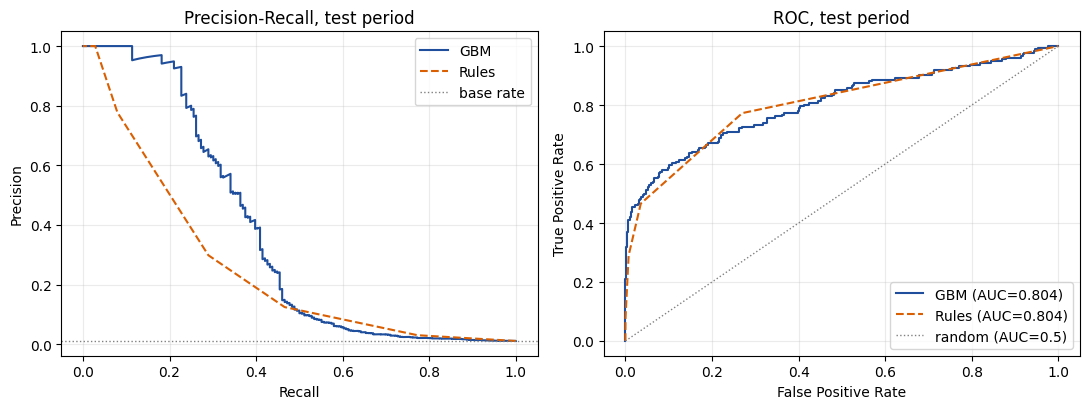

In [23]:
# Trains XGBoost on the train split, scores calib/test. Builds a simple hand-coded "rules" baseline
# to compare against. Evaluates both with PR-AUC/ROC-AUC and precision/recall at the top 0.5% scored.
# Output: metrics table (GBM should beat rules on PR-AUC and ROC-AUC) + PR curve and ROC curve side by
# side. On the PR plot, GBM's curve should sit above Rules and well above the flat base-rate line.
# On the ROC plot, GBM's curve should bulge toward the top-left, above the diagonal (= random guessing).
neg, pos = (y[tr] == 0).sum(), y[tr].sum()
model = (XGBClassifier(
    n_estimators=300, max_depth=4, learning_rate=.05,
      subsample=.8, colsample_bytree=.8,
      scale_pos_weight=neg / pos, eval_metric="aucpr", random_state=42, n_jobs=-1))

model.fit(X[tr], y[tr])
raw = {"ca": model.predict_proba(X[ca])[:, 1], "te": model.predict_proba(X[te])[:, 1]}

def rules(d):
    return (2*(d.amount_ratio > 3) + 2*(d.n_1h >= 3) + 2*d.new_device + d.foreign
            + ((d.is_night == 1) & (d.channel == "ecom")) + d["cat"].isin(RISKY)).astype(float)

df_te, yt = df[te], y[te]
r_te = rules(df_te).values

def evaluate(name, s, yy, frac=.005):# top-frac = analyst review budget
    k = int(len(yy) * frac); top = np.argsort(-s, kind="stable")[:k]
    return dict(model=name, PR_AUC=average_precision_score(yy, s), ROC_AUC=roc_auc_score(yy, s),
                **{f"precision@top{frac:.1%}": yy[top].mean(), f"recall@top{frac:.1%}": yy[top].sum() / yy.sum()})

print(f"test base rate (random PR-AUC): {yt.mean():.4f}")
print(pd.DataFrame([evaluate("rules", r_te, yt), evaluate("GBM", raw["te"], yt)]).set_index("model").round(3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
for name, s, ls, col in [("GBM", raw["te"], "-", "#1f4e9c"), ("Rules", r_te, "--", "#d95f02")]:
    p, r, _ = precision_recall_curve(yt, s); ax1.plot(r, p, ls, color=col, label=name)
    fpr, tpr, _ = roc_curve(yt, s); ax2.plot(fpr, tpr, ls, color=col, label=f"{name} (AUC={roc_auc_score(yt, s):.3f})")

ax1.axhline(yt.mean(), color="gray", lw=1, ls=":", label="base rate")
ax1.set(xlabel="Recall", ylabel="Precision", title="Precision-Recall, test period"); ax1.legend(); ax1.grid(alpha=.25)

ax2.plot([0, 1], [0, 1], color="gray", lw=1, ls=":", label="random (AUC=0.5)")
ax2.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="ROC, test period"); ax2.legend(); ax2.grid(alpha=.25)

plt.tight_layout(); plt.show()

actual frauds in test : 176
sum of raw scores     :     3118   Brier 0.06144
sum of calibrated p   :      144   Brier 0.00813


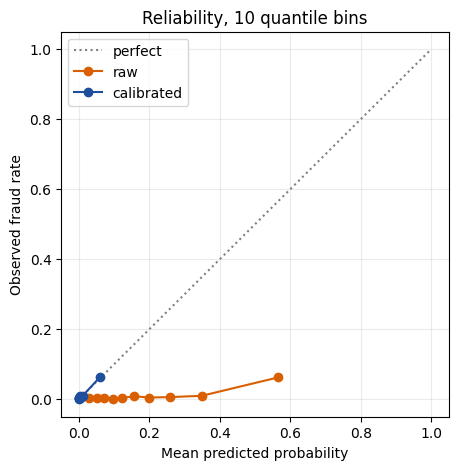

In [15]:
# Calibrates raw model scores into true probabilities via Platt scaling, fit on the CALIB split
# (never on test - avoids leakage). Checks if calibrated probabilities sum closer to the actual fraud count.
# Output: sum of raw vs calibrated scores vs actual frauds, Brier score (lower = better calibrated),
# and a reliability plot - calibrated dots should hug the diagonal more closely than raw dots.
logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
platt = LogisticRegression(C=1e6).fit(logit(raw["ca"]).reshape(-1, 1), y[ca])
cal = lambda s: platt.predict_proba(logit(s).reshape(-1, 1))[:, 1]
p_te = cal(raw["te"])

print(f"actual frauds in test : {yt.sum()}")
print(f"sum of raw scores     : {raw['te'].sum():8.0f}   Brier {brier_score_loss(yt, raw['te']):.5f}")
print(f"sum of calibrated p   : {p_te.sum():8.0f}   Brier {brier_score_loss(yt, p_te):.5f}")

fig, ax = plt.subplots(figsize=(5, 5)); ax.plot([0, 1], [0, 1], ":", color="gray", label="perfect")
for name, p, col in [("raw", raw["te"], "#d95f02"), ("calibrated", p_te, "#1f4e9c")]:
    f, m = calibration_curve(yt, p, n_bins=10, strategy="quantile"); ax.plot(m, f, "o-", color=col, label=name)
ax.set(xlabel="Mean predicted probability", ylabel="Observed fraud rate", title="Reliability, 10 quantile bins")
ax.legend(); ax.grid(alpha=.25); plt.show()

In [16]:
# Buckets calibrated probabilities into risk bands and compares each band's predicted rate to its
# actual observed fraud rate - a more granular calibration check than the single Brier score above.
# Output: txns/frauds/observed_rate/mean_p per band. observed_rate and mean_p should be close within
# each band; a big gap means that specific risk band is miscalibrated.
b = pd.DataFrame({"band": pd.cut(p_te, [0, .005, .02, .10, 1.0001], labels=["<0.5%", "0.5-2%", "2-10%", ">10%"]),
                  "fraud": yt, "p": p_te})
print(b.groupby("band", observed=True).agg(txns=("fraud", "size"), frauds=("fraud", "sum"),
                                           observed_rate=("fraud", "mean"), mean_p=("p", "mean")).round(4))

         txns  frauds  observed_rate  mean_p
band                                        
<0.5%   11583      48         0.0041  0.0017
0.5-2%   3678      32         0.0087  0.0097
2-10%    1027      31         0.0302  0.0385
>10%      141      65         0.4610  0.3462


In [17]:
# Converts probabilities into approve/review/decline decisions by minimizing EXPECTED cost per txn,
# using business cost assumptions (review cost, false-positive cost, etc). Compares against
# approve-all, the hand-coded rules baseline, and a simple "review top 0.5% by score" policy.
# Output: action counts, fraud loss, ops friction, and total cost per strategy. Check "saving_vs_approve_all" -
# the cost-optimal GBM policy should show the largest saving.
COSTS = dict(review=12, review_effect=.9, review_friction=2, fp_fixed=40, margin=.05)   # ASSUMPTIONS, tune to your business
amt = df_te.amount.values
ACTIONS = np.array(["approve", "review", "decline"])

def expected(p, a):
    return np.column_stack([p * a,                                                          # approve: risk the full amount
                            COSTS["review"] + p*a*(1 - COSTS["review_effect"]) + (1 - p)*COSTS["review_friction"],
                            (1 - p) * (COSTS["fp_fixed"] + COSTS["margin"] * a)])                   # decline: cost of blocking a good txn

def realized(act, yy, a):
    ap, rv, dc = act == "approve", act == "review", act == "decline"
    loss = (yy * a)[ap].sum() + (yy * a * (1 - COSTS["review_effect"]))[rv].sum()
    ops = (COSTS["review"] * rv.sum() + (COSTS["review_friction"] * (1 - yy))[rv].sum()
           + ((1 - yy) * (COSTS["fp_fixed"] + COSTS["margin"] * a))[dc].sum())
    return dict(approve=ap.sum(), review=rv.sum(), decline=dc.sum(), fraud_loss=loss, ops_friction=ops, total=loss + ops)

act_model = ACTIONS[expected(p_te, amt).argmin(1)]
act_rules = np.where(r_te >= 5, "decline", np.where(r_te >= 3, "review", "approve"))
k = int(len(yt) * .005); act_topk = np.full(len(yt), "approve"); act_topk[np.argsort(-p_te)[:k]] = "review"
res = pd.DataFrame({"approve all": realized(np.full(len(yt), "approve"), yt, amt),
                    "rules": realized(act_rules, yt, amt),
                    "GBM top-0.5% review": realized(act_topk, yt, amt),
                    "GBM cost-optimal": realized(act_model, yt, amt)}).T
res["saving_vs_approve_all"] = 1 - res.total / res.loc["approve all", "total"]
print(res.round(2).to_string())

                     approve  review  decline  fraud_loss  ops_friction     total  saving_vs_approve_all
approve all          16429.0     0.0      0.0    15133.82          0.00  15133.82                   0.00
rules                16258.0   166.0      5.0     9016.25       2232.00  11248.25                   0.26
GBM top-0.5% review  16347.0    82.0      0.0     8482.81       1044.00   9526.81                   0.37
GBM cost-optimal     16340.0    55.0     34.0     7624.99        820.18   8445.17                   0.44


In [18]:
# For the riskiest test transactions, explains WHY the model flagged them: zero out each feature
# group (device, amount, velocity, etc) one at a time and measure how much the predicted probability drops.
# Output: top-8 riskiest transactions with probability, actual label, action taken, and a plain-language
# "why". Most "actual" values should be 1 (real fraud), confirming the top scores are trustworthy.
cols = list(X.columns); cat_c = [c for c in cols if c.startswith("cat_")]; ch_c = [c for c in cols if c.startswith("ch_")]
GROUPS = {"new_device": ["new_device"], "amount_vs_usual": ["amount", "log_amount", "amount_ratio"],
          "velocity": ["n_1h", "n_24h", "amt_24h_ratio"], "time_of_day": ["hour", "is_night"], "foreign": ["foreign"],
          "merchant_category": cat_c, "channel": ch_c, "recency": ["since_last"], "history": ["prior_n"]}
base_row = X[tr & (y == 0)].median()
base_row[cat_c] = 0; base_row["cat_grocery"] = 1; base_row[ch_c] = 0; base_row["ch_pos"] = 1   # a typical legit txn

def reasons(i, top=3):
    x = X[te].iloc[i]; p0 = model.predict_proba(x.to_frame().T)[0, 1]; drops = {}
    for gname, c in GROUPS.items():
        x2 = x.copy(); x2[c] = base_row[c]; drops[gname] = p0 - model.predict_proba(x2.to_frame().T)[0, 1]
    return [k_ for k_, v in sorted(drops.items(), key=lambda kv: -kv[1])[:top] if v > 0]

TEXT = {"new_device": lambda r: "new device", "amount_vs_usual": lambda r: f"amount {r.amount_ratio:.1f}x usual",
        "velocity": lambda r: f"{int(r.n_1h)} txns in last hour", "time_of_day": lambda r: f"hour {int(r.hour):02d}:00",
        "foreign": lambda r: "foreign", "merchant_category": lambda r: f"category {r['cat']}",
        "channel": lambda r: f"channel {r['channel']}", "recency": lambda r: "burst timing", "history": lambda r: "thin history"}
order = np.argsort(-p_te)[:8]
print(pd.DataFrame({"amount": amt[order], "p_fraud": p_te[order].round(3), "actual": yt[order], "action": act_model[order],
                    "why": [", ".join(TEXT[g_](df_te.iloc[i]) for g_ in reasons(i)) for i in order]}).to_string())

   amount  p_fraud  actual   action                                                       why
0  163.87    0.989       1  decline      channel wallet, category crypto, 3 txns in last hour
1   95.94    0.980       1  decline      channel wallet, 7 txns in last hour, category travel
2  188.00    0.975       1  decline      channel wallet, category travel, 8 txns in last hour
3  240.51    0.974       1  decline      category crypto, 4 txns in last hour, channel wallet
4  243.19    0.970       1  decline  5 txns in last hour, category gift_cards, channel wallet
5   97.44    0.964       1  decline      4 txns in last hour, channel wallet, category crypto
6   58.93    0.959       1  decline      channel wallet, category travel, 2 txns in last hour
7  269.54    0.950       1  decline      channel wallet, category crypto, 3 txns in last hour


In [19]:
# Monitors for model drift using PSI (Population Stability Index), comparing the test-period score
# distribution to the calibration period, day by day. Also simulates an artificial feature shift to
# confirm PSI actually reacts. Tracks daily review precision as an operational health check.
# Output: daily PSI values (<0.1 = stable, >0.25 = investigate) - should stay low on real test days,
# while the artificial shift should produce a noticeably higher PSI, proving the metric works.
def psi(ref, cur, bins=10):
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    a = np.histogram(ref, edges)[0] / len(ref) + 1e-6; b_ = np.histogram(cur, edges)[0] / len(cur) + 1e-6
    return float(np.sum((b_ - a) * np.log(b_ / a)))

p_ref, day_te = cal(raw["ca"]), df_te.day.values
print("daily PSI vs calibration period (<0.1 stable):",
      {int(d): round(psi(p_ref, p_te[day_te == d]), 3) for d in np.unique(day_te)})
Xs = X[te].copy(); Xs["amount_ratio"] *= 3; Xs["n_1h"] *= 4                          # ARTIFICIAL shift, to see PSI react
print("PSI under artificial shift:", round(psi(p_ref, cal(model.predict_proba(Xs)[:, 1])), 3))

flag = act_model != "approve"
print(pd.DataFrame({"day": day_te, "flag": flag, "fraud": yt}).query("flag").groupby("day").fraud
      .agg(flagged="size", confirmed="sum", precision="mean").round(3))

daily PSI vs calibration period (<0.1 stable): {50: 0.01, 51: 0.006, 52: 0.012, 53: 0.016, 54: 0.016, 55: 0.021, 56: 0.028, 57: 0.022, 58: 0.046, 59: 0.038}
PSI under artificial shift: 0.039
     flagged  confirmed  precision
day                               
50        13         10      0.769
51         9          4      0.444
52         3          0      0.000
53         4          1      0.250
54         4          0      0.000
55         6          1      0.167
56        15         10      0.667
57        17         15      0.882
58        13          9      0.692
59         5          3      0.600
